In [1]:
import cv2 as cv
import PIV_preprocess_functions as piv_im
import PIV_functions as piv_f
import PIV_postfunct as piv_post
import numpy as np
import matplotlib.pyplot as plt
import os
import scipy.signal as signl
from scipy import stats
import pandas as pd
from IPython.display import clear_output

# The processed example

/home/viesturs/.conda/envs/spyder_vision/lib/python3.13/site-packages/numpy/_core/fromnumeric.py:3824: RuntimeWarning: Mean of empty slice
  return _methods._mean(a, axis=axis, dtype=dtype,
/home/viesturs/.conda/envs/spyder_vision/lib/python3.13/site-packages/numpy/_core/_methods.py:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


Saving to /more/Ex/piv/PIV_output/OpenPIV_results_48_1_/field_A0000.txt
Image Pair 1
Frame_1 Frame_2


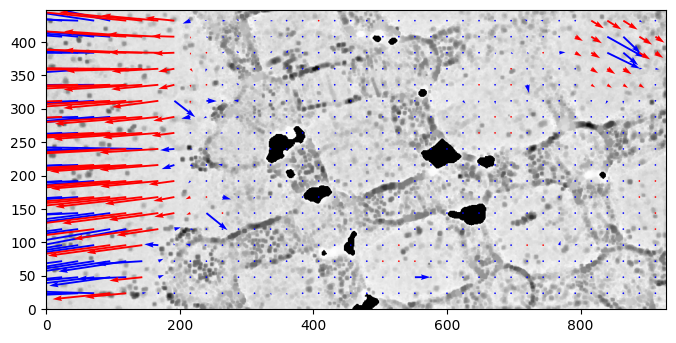

In [2]:
im_folder = "/more/Ex/piv/"

windows = (128, 64, 48)
overlaps = (64, 32, 24)
frame_n = 1;
ch = 3;
settings = piv_f.settings_set_genex1(im_folder, ch, 'enhanced',
                                      windows, overlaps,
                                    iter_n = len(windows),
                               std_thresh = 10, med_thresh = 3, normc = True)

piv_f.do_piv_mt_genex1(settings, frame_n)
piv_f.displayer_mt2_genex1(fn = 0, im_folder = im_folder +
                            "ch" + str(ch) + "/", window=windows[-1])

## For windows

In [ ]:
import pathlib

im_folder = pathlib.Path("/more/Ex/piv/")

windows = (128, 64, 48)
overlaps = (64, 32, 24)

frame_n = 1
ch = 3

settings = piv_f.settings_set_genex1(
    str(im_folder),
    ch,
    'enhanced',
    windows,
    overlaps,
    iter_n=len(windows),
    std_thresh=10,
    med_thresh=3,
    normc=True
)

piv_f.do_piv_mt_genex1(settings, frame_n)

piv_f.displayer_mt2_genex1(
    fn=0,
    im_folder=str(im_folder / f"ch{ch}"),
    window=windows[-1]
)

# The parallel

In [3]:
import tqdm
import numpy as np
import multiprocessing

def piv_wrapper(args):
    return piv_f.piv_row_parallel_mt1_genex1(*args)

core_n = 10

im_folder = "/more/Ex/piv/"
windows = (128, 64)
overlaps = (64, 32)

iter_n = len(windows)
std_thresh = 1
med_thresh = 0.8

from_ch = 3; ch_to = 3; ch_n = ch_to - from_ch + 1

slice_pile = np.linspace(from_ch, ch_to, num=ch_n)

settings_X = [(im_folder, slith, 'enhanced', windows, overlaps,
                                  iter_n, std_thresh, med_thresh) for slith 
                                  in range(from_ch, ch_to + 1)]

pool = multiprocessing.Pool(core_n)
#pool.starmap(piv_f.piv_row_parallel_skip, settings_X)

for _ in tqdm.tqdm(
    pool.imap_unordered(piv_wrapper, settings_X),
    total=len(settings_X),
    desc="Processing slices"
):
    pass

pool.close()
pool.join()

Processing slices: 100%|██████████| 1/1 [00:42<00:00, 42.58s/it]


## For windows

In [ ]:
import tqdm
import numpy as np
import multiprocessing
import pathlib


def piv_wrapper(args):
    return piv_f.piv_row_parallel_mt1_genex1(*args)


core_n = 10

im_folder = pathlib.Path("/more/Ex/piv/")

windows = (128, 64)
overlaps = (64, 32)

iter_n = len(windows)
std_thresh = 1
med_thresh = 0.8

from_ch = 3
ch_to = 3
ch_n = ch_to - from_ch + 1

slice_pile = np.linspace(from_ch, ch_to, num=ch_n)

settings_X = [
    (
        str(im_folder),
        slith,
        'enhanced',
        windows,
        overlaps,
        iter_n,
        std_thresh,
        med_thresh
    )
    for slith in range(from_ch, ch_to + 1)
]


if __name__ == '__main__':

    pool = multiprocessing.Pool(core_n)

    try:
        for _ in tqdm.tqdm(
            pool.imap_unordered(piv_wrapper, settings_X),
            total=len(settings_X),
            desc="Processing slices"
        ):
            pass

    finally:
        pool.close()
        pool.join()